# Practical 8: Graph-Based Recommender System Using GNN

## Aim

To model MovieLens Small as a **bipartite user-movie interaction graph**, implement a **LightGCN-style graph neural recommender**, generate Top-N recommendations, evaluate ranking performance, and analyze user-item interaction patterns.

The graph contains:

- user nodes
- movie nodes
- positive user-movie interaction edges

The propagation rule is:

$
E^{(l+1)} = D^{-1/2} A D^{-1/2} E^{(l)}
$

The model is trained with Bayesian Personalized Ranking (BPR) so that a user's observed positive movie receives a higher score than an unobserved negative movie.

In [4]:
from google.colab import drive; drive.mount("/content/drive")
import random
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
import torch, torch.nn as nn, torch.nn.functional as F

DATA_FOLDER = "/content/drive/MyDrive/mlsmall"
POSITIVE_THRESHOLD = 4.0
EMBEDDING_DIM, NUM_LAYERS = 64, 2
LEARNING_RATE, WEIGHT_DECAY = 0.01, 1e-4
BATCH_SIZE, EPOCHS = 2048, 30
TOP_N = RANKING_K = 10
DEMO_USER_ID = 25
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(42); np.random.seed(42); torch.manual_seed(42)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load MovieLens Small

In [5]:
ratings = pd.read_csv(f"{DATA_FOLDER}/ratings.csv")
movies  = pd.read_csv(f"{DATA_FOLDER}/movies.csv")
titles  = movies.drop_duplicates("movieId").set_index("movieId")["title"]

print("Ratings shape:", ratings.shape, "| Movies shape:", movies.shape)
print("Users:", ratings.userId.nunique(), "| Rated movies:", ratings.movieId.nunique(), "| Ratings:", len(ratings))
print("Device:", DEVICE)
display(ratings.head(), movies.head())

Ratings shape: (100836, 4) | Movies shape: (9742, 3)
Users: 610 | Rated movies: 9724 | Ratings: 100836
Device: cpu


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 2. Explicit ratings → positive graph edges
An edge means the user positively interacted with the movie (`rating >= POSITIVE_THRESHOLD`). Users need ≥ 3 positives: earlier ones → training graph, second-last → validation, last → test.

In [6]:
positive = (ratings[ratings.rating >= POSITIVE_THRESHOLD].sort_values(["userId", "timestamp"]).reset_index(drop=True))
print("POSITIVE INTERACTION GRAPH")
print("Positive interactions:", len(positive))
print("Users with positive interactions:", positive.userId.nunique())
print("Movies with positive interactions:", positive.movieId.nunique())

counts = positive.userId.value_counts()
positive = positive[positive.userId.isin(counts[counts >= 3].index)].copy()
print("\nEligible users:", positive.userId.nunique())

from_end = positive.groupby("userId").cumcount(ascending=False)      # 0 = latest positive of each user
train_data, validation_data, test_data = positive[from_end >= 2], positive[from_end == 1], positive[from_end == 0]
print("Training positive edges:", len(train_data), "| Validation edges:", len(validation_data), "| Test edges:", len(test_data))

POSITIVE INTERACTION GRAPH
Positive interactions: 48580
Users with positive interactions: 609
Movies with positive interactions: 6298

Eligible users: 608
Training positive edges: 47363 | Validation edges: 608 | Test edges: 608


## 3. Compact user and movie ID mappings
User nodes are `0 … NUM_USERS-1`; movie nodes follow as `NUM_USERS … NUM_USERS+NUM_MOVIES-1`.

In [7]:
user_ids  = np.sort(positive.userId.unique())
movie_ids = np.sort(positive.movieId.unique())
user_to_index  = {u: i for i, u in enumerate(user_ids)}
movie_to_index = {m: i for i, m in enumerate(movie_ids)}
NUM_USERS, NUM_MOVIES = len(user_ids), len(movie_ids)

print("Number of user nodes :", NUM_USERS)
print("Number of movie nodes:", NUM_MOVIES)
print("Total graph nodes    :", NUM_USERS + NUM_MOVIES)

Number of user nodes : 608
Number of movie nodes: 6298
Total graph nodes    : 6906


## 4. Analyse user-item interaction patterns

GRAPH INTERACTION PATTERNS
Graph density : 0.012369
Graph sparsity: 0.987631
Average positive interactions per user : 77.9
Average positive interactions per movie: 7.52

Most active users


,userId,Training Positive Degree
0,414,1225
1,474,785
2,380,667
3,610,612
4,606,611
5,603,561
6,105,552
7,249,509
8,182,486
9,448,453


Most connected movies


,movieId,Movie,Training Positive Degree
0,318,"Shawshank Redemption, The (1994)",270
1,356,Forrest Gump (1994),244
2,296,Pulp Fiction (1994),241
3,593,"Silence of the Lambs, The (1991)",220
4,2571,"Matrix, The (1999)",220
5,260,Star Wars: Episode IV - A New Hope (1977),199
6,2959,Fight Club (1999),179
7,527,Schindler's List (1993),168
8,1196,Star Wars: Episode V - The Empire Strikes Back...,166
9,110,Braveheart (1995),163


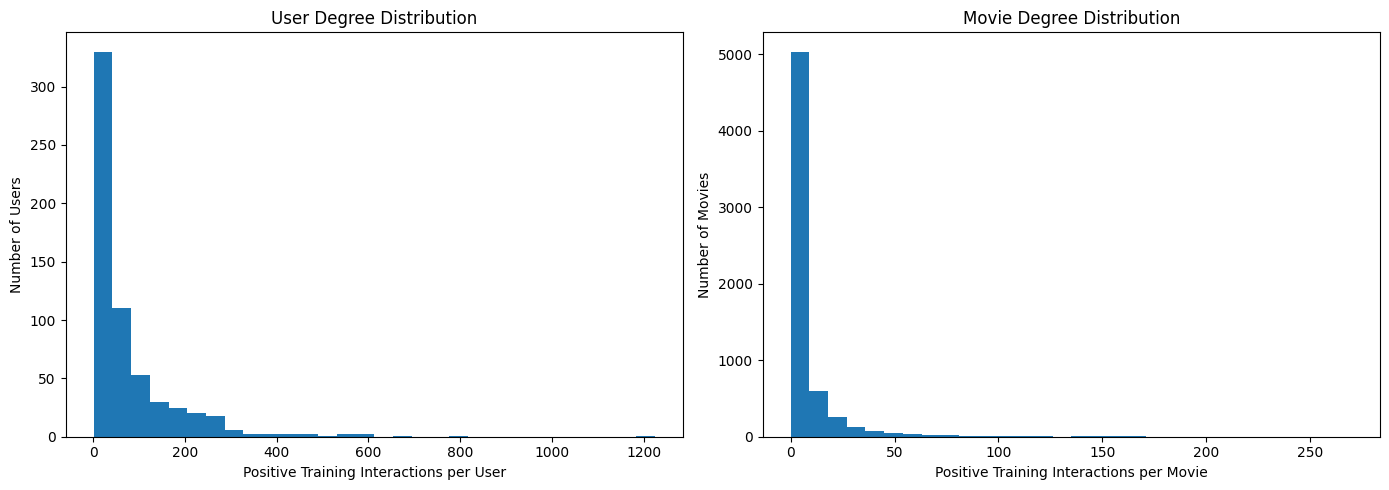

In [8]:
user_degree  = train_data.userId.value_counts().reindex(user_ids, fill_value=0)
movie_degree = train_data.movieId.value_counts().reindex(movie_ids, fill_value=0)
graph_density = len(train_data) / (NUM_USERS * NUM_MOVIES)

print("GRAPH INTERACTION PATTERNS")
print(f"Graph density : {graph_density:.6f}")
print(f"Graph sparsity: {1 - graph_density:.6f}")
print("Average positive interactions per user :", round(user_degree.mean(), 2))
print("Average positive interactions per movie:", round(movie_degree.mean(), 2))

print("\nMost active users")
display(user_degree.nlargest(10).rename_axis("userId").reset_index(name="Training Positive Degree"))

top_movies = movie_degree.nlargest(10).rename_axis("movieId").reset_index(name="Training Positive Degree")
top_movies.insert(1, "Movie", top_movies.movieId.map(titles))
print("Most connected movies")
display(top_movies)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(user_degree.values, bins=30)
ax[0].set(xlabel="Positive Training Interactions per User", ylabel="Number of Users", title="User Degree Distribution")
ax[1].hist(movie_degree.values, bins=30)
ax[1].set(xlabel="Positive Training Interactions per Movie", ylabel="Number of Movies", title="Movie Degree Distribution")
plt.tight_layout(); plt.show()

## 5. A small bipartite interaction subgraph
The 5 most active users and the 12 movies they most often share.

In [ ]:
top_users = user_degree.nlargest(5).index
sub = train_data[train_data.userId.isin(top_users)]
sub_movies = sub.movieId.value_counts().head(12).index
sub = sub[sub.movieId.isin(sub_movies)]

u_nodes = [f"U{u}" for u in top_users]
m_nodes = [f"M{m}" for m in sub_movies]
G = nx.Graph()
G.add_nodes_from(u_nodes + m_nodes)
G.add_edges_from((f"U{r.userId}", f"M{r.movieId}") for r in sub.itertuples())

layout = {n: (0, i) for i, n in enumerate(u_nodes)} | {n: (1, i) for i, n in enumerate(m_nodes)}
labels = {n: n for n in u_nodes} | {f"M{m}": titles.get(m, str(m))[:20] for m in sub_movies}

plt.figure(figsize=(12, 7))
nx.draw(G, layout, labels=labels, node_size=700, font_size=8, alpha=0.9,
        node_color=["tab:blue"] * len(u_nodes) + ["tab:orange"] * len(m_nodes), edge_color="gray")
plt.title("Sample User-Movie Bipartite Interaction Graph"); plt.show()

## 6. Training edges and positive sets
The sets are used for negative sampling and for hiding already-seen movies at recommendation time.

In [ ]:
train_u = train_data.userId.map(user_to_index).to_numpy(np.int64)
train_m = train_data.movieId.map(movie_to_index).to_numpy(np.int64)

train_positive_sets = {u: set() for u in range(NUM_USERS)}
for u, m in zip(train_u.tolist(), train_m.tolist()):
    train_positive_sets[u].add(m)

## 7. Normalised bipartite adjacency matrix

Each user–movie edge is made bidirectional, then normalised symmetrically:

$$\hat A = D^{-1/2} A D^{-1/2}$$

LightGCN propagation then uses $E^{(l+1)} = \hat A\,E^{(l)}$.

In [ ]:
def build_normalized_adjacency(user_idx, movie_idx, num_users, num_movies, device):
    """Sparse (U+M) x (U+M) matrix  D^-1/2 A D^-1/2  built from the training edges."""
    movie_nodes = movie_idx + num_users
    row = np.concatenate([user_idx, movie_nodes])
    col = np.concatenate([movie_nodes, user_idx])
    n = num_users + num_movies

    degree = np.bincount(row, minlength=n).astype(np.float32)
    inv_sqrt = np.divide(1.0, np.sqrt(degree), out=np.zeros_like(degree), where=degree > 0)
    values = inv_sqrt[row] * inv_sqrt[col]

    adj = torch.sparse_coo_tensor(torch.tensor(np.vstack([row, col]), dtype=torch.long),
                                  torch.tensor(values, dtype=torch.float32), size=(n, n))
    return adj.coalesce().to(device)

normalized_adj = build_normalized_adjacency(train_u, train_m, NUM_USERS, NUM_MOVIES, DEVICE)
print("Normalized adjacency shape:", tuple(normalized_adj.shape))
print("Number of directed sparse entries:", normalized_adj._nnz())

## 8. LightGCN model
LightGCN removes feature transforms and non-linearities and keeps only neighbourhood aggregation. The final embedding is the **mean of layers 0…L**; a user–movie score is the dot product of their final embeddings.

In [ ]:
class LightGCN(nn.Module):
    def __init__(self, num_users, num_movies, embedding_dim=64, num_layers=2):
        super().__init__()
        self.num_users, self.num_layers = num_users, num_layers
        self.user_embedding  = nn.Embedding(num_users, embedding_dim)
        self.movie_embedding = nn.Embedding(num_movies, embedding_dim)
        nn.init.normal_(self.user_embedding.weight, std=0.1)
        nn.init.normal_(self.movie_embedding.weight, std=0.1)

    def propagate(self, adj):
        """E(l+1) = D^-1/2 A D^-1/2 E(l); returns the mean of the layer embeddings, split into users / movies."""
        current = torch.cat([self.user_embedding.weight, self.movie_embedding.weight], dim=0)
        layers = [current]
        for _ in range(self.num_layers):
            current = torch.sparse.mm(adj, current)
            layers.append(current)
        final = torch.stack(layers, dim=0).mean(0)
        return final[:self.num_users], final[self.num_users:]

model = LightGCN(NUM_USERS, NUM_MOVIES, EMBEDDING_DIM, NUM_LAYERS).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
print("LIGHTGCN MODEL"); print(model)

## 9. Negative sampling and BPR loss

For every positive `(user, movie)` edge, sample one movie the user has **not** positively interacted with. BPR wants

`score(user, positive) > score(user, negative)`

with loss `-log sigmoid(pos_score - neg_score)`.

In [ ]:
def sample_negative_movies(users, positive_sets, num_movies):
    negatives = np.random.randint(0, num_movies, len(users))
    for i, u in enumerate(users.tolist()):
        while negatives[i] in positive_sets[u]:
            negatives[i] = np.random.randint(num_movies)
    return negatives

def bpr_loss(user_emb, pos_emb, neg_emb):
    return -F.logsigmoid((user_emb * pos_emb).sum(1) - (user_emb * neg_emb).sum(1)).mean()

## 10. Train LightGCN

In [ ]:
tensor = lambda a: torch.tensor(a, dtype=torch.long, device=DEVICE)
loss_history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = np.random.permutation(len(train_u))
    total, batches = 0.0, 0

    for start in range(0, len(perm), BATCH_SIZE):
        b = perm[start:start + BATCH_SIZE]
        u_b, pos_b = train_u[b], train_m[b]
        neg_b = sample_negative_movies(u_b, train_positive_sets, NUM_MOVIES)

        optimizer.zero_grad()
        user_emb, movie_emb = model.propagate(normalized_adj)
        loss = bpr_loss(user_emb[tensor(u_b)], movie_emb[tensor(pos_b)], movie_emb[tensor(neg_b)])
        loss.backward()
        optimizer.step()

        total += loss.item(); batches += 1

    loss_history.append(total / batches)
    print(f"Epoch {epoch:02d} | BPR Loss = {loss_history[-1]:.6f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), loss_history)
plt.xlabel("Epoch"); plt.ylabel("BPR Loss"); plt.title("LightGCN Training Loss")
plt.tight_layout(); plt.show()

## 11. Final embeddings and Top-N recommendations

In [ ]:
model.eval()
with torch.no_grad():
    final_users, final_movies = model.propagate(normalized_adj)

def scores_for(user_id, mask_seen=True):
    """Dot-product score of every movie for one user (training positives hidden if mask_seen)."""
    ui = user_to_index[user_id]
    s = (final_movies @ final_users[ui]).cpu().numpy()
    if mask_seen:
        s[list(train_positive_sets[ui])] = -np.inf
    return s

def recommend_movies(user_id, top_n=TOP_N):
    s = scores_for(user_id)
    top = np.argsort(-s)[:top_n]
    return pd.DataFrame({"Rank": range(1, len(top) + 1), "movieId": movie_ids[top],
                         "Movie": titles.reindex(movie_ids[top]).values, "GNN Score": s[top]})

if DEMO_USER_ID not in user_to_index:
    DEMO_USER_ID = int(user_ids[0])

demo_recs = recommend_movies(DEMO_USER_ID)
print(f"TOP {TOP_N} GNN RECOMMENDATIONS FOR USER {DEMO_USER_ID}")
display(demo_recs)

d = demo_recs.sort_values("GNN Score")
plt.figure(figsize=(10, 6)); plt.barh(d["Movie"], d["GNN Score"])
plt.xlabel("GNN Recommendation Score"); plt.ylabel("Movie"); plt.title(f"Top LightGCN Recommendations for User {DEMO_USER_ID}")
plt.tight_layout(); plt.show()

## 12. Ranking evaluation
Rank of each user's held-out (latest) positive movie among the movies they have not seen in training → HR@10, MRR@10, NDCG@10.

In [ ]:
ranks = np.array([int(np.sum(s > s[movie_to_index[r.movieId]])) + 1
                  for r in test_data.itertuples() for s in [scores_for(r.userId)]])
hit = ranks <= RANKING_K

evaluation_results = test_data[["userId", "movieId"]].assign(
    Rank=ranks, **{f"Hit@{RANKING_K}": hit.astype(int),
                   f"RR@{RANKING_K}": np.where(hit, 1 / ranks, 0.0),
                   f"NDCG@{RANKING_K}": np.where(hit, 1 / np.log2(ranks + 1), 0.0)})
hit_rate, mrr_at_k, ndcg_at_k = (evaluation_results[f"{m}@{RANKING_K}"].mean() for m in ("Hit", "RR", "NDCG"))

print("GNN RANKING EVALUATION")
print(f"Hit Rate@{RANKING_K}: {hit_rate:.4f}")
print(f"MRR@{RANKING_K}: {mrr_at_k:.4f}")
print(f"NDCG@{RANKING_K}: {ndcg_at_k:.4f}")
display(evaluation_results.head(15))

## 13. Movie degree vs learned GNN score
For the demo user (training positives *not* hidden here), compare a movie's popularity in the training graph with its learned score.

In [ ]:
pattern = pd.DataFrame({"movieId": movie_ids, "Training Degree": movie_degree.values,
                        "GNN Score": scores_for(DEMO_USER_ID, mask_seen=False)})
pattern["Movie"] = pattern.movieId.map(titles)

print("Movie interaction pattern sample")
display(pattern.sort_values("GNN Score", ascending=False).head(15))

plt.figure(figsize=(8, 5))
plt.scatter(pattern["Training Degree"], pattern["GNN Score"], alpha=0.5)
plt.xlabel("Movie Training Degree"); plt.ylabel("GNN Score for Demo User")
plt.title("Interaction Degree vs Learned GNN Recommendation Score")
plt.tight_layout(); plt.show()

## 14. Learned movie embeddings in 2D (SVD)
Only for visualisation - the recommender uses the full embedding dimension.

In [ ]:
E = final_movies.detach().cpu().numpy()
E = E - E.mean(axis=0, keepdims=True)
U, S, _ = np.linalg.svd(E, full_matrices=False)
xy = U[:, :2] * S[:2]

plt.figure(figsize=(9, 7))
plt.scatter(xy[:, 0], xy[:, 1], alpha=0.35)
for m in movie_degree.nlargest(20).index:                     # label only the most connected movies
    plt.annotate(titles.get(m, str(m))[:20], xy[movie_to_index[m]], fontsize=7)
plt.xlabel("Embedding Dimension 1"); plt.ylabel("Embedding Dimension 2"); plt.title("2D View of Learned Movie Graph Embeddings")
plt.tight_layout(); plt.show()

## 15. Summary

In [ ]:
print("PRACTICAL 8 SUMMARY")
print("Model: LightGCN-style graph neural recommender | Graph: bipartite user-movie interaction graph")
print("Positive interaction threshold:", POSITIVE_THRESHOLD)
print("Training graph users:", NUM_USERS, "| movies:", NUM_MOVIES, "| positive edges:", len(train_data))
print("Embedding dimension:", EMBEDDING_DIM, "| Propagation layers:", NUM_LAYERS, f"| Graph density: {graph_density:.6f}")
print(f"Hit Rate@{RANKING_K}: {hit_rate:.4f} | MRR@{RANKING_K}: {mrr_at_k:.4f} | NDCG@{RANKING_K}: {ndcg_at_k:.4f}")

**Workflow**

```
MovieLens positive ratings
        ↓
User-movie bipartite graph
        ↓
Analyse user/movie node degrees
        ↓
Temporal train / validation / test edges
        ↓
Trainable user and movie embeddings
        ↓
Normalized graph message passing
        ↓
LightGCN propagated embeddings
        ↓
BPR positive-vs-negative ranking loss
        ↓
User-movie dot-product scores
        ↓
Top-N recommendations
        ↓
HR@10 / MRR@10 / NDCG@10
        ↓
Analyse degree patterns and learned embeddings
```